In [53]:
import lightning as L
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import awkward as ak
import pyarrow as pa
import pyarrow.parquet as pq
import global_data_utils
import vector
import fastjet
import zlib
import pandas as pd
import os
import socket
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

Loading data

In [54]:
jz_path = "path_to_data.parquet"
ggf_path = "path_to_data.parquet"

In [55]:
import psutil
import os


Node total RAM:     503.19 GiB
Node available RAM: 456.34 GiB
This Python kernel is using: 12.01 GiB


In [56]:
import os

print("Job ID:", os.environ.get("SLURM_JOB_ID"))
print("Memory per node:", os.environ.get("SLURM_MEM_PER_NODE"))

Job ID: 48568
Memory per node: 65536


Training Settings

In [57]:
SEED = 42

BATCH_SIZE = 64
N_EPOCHS = 30

#MAX_BATCHES = 600
#MAX_VAL_BATCHES = 100

LEARNING_RATE = 3e-4

# Original baseline bottleneck.
LATENT_CHANNELS = 16

# Final loss settings.
ALPHA = 10.0
ACTIVE_LAMBDA = 0.1
LOCAL_LAMBDA = 1.0

LOCAL_WINDOW_SIZE = 7
ACTIVE_TOWER_THRESHOLD_GEV = 1.0


# 10 batches x 256 events.
SCALE_BATCH_SIZE = 256
SCALE_MAX_BATCHES = 10
SCALE_PERCENTILE = 0.999


NUM_WORKERS = 0

# First run only the original 32-channel baseline.

RUN_LATENT_SCAN = False

LATENT_CHANNEL_SCAN = [
    4,
    8,
    16,
    32,
]

In [58]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

L.seed_everything(
    SEED,
    workers=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

[rank: 0] Seed set to 42


Device: cuda
GPU: NVIDIA A100 80GB PCIe


loading events

In [59]:
# ============================================================
# EVENT-BATCH LOADER
# ============================================================

def iter_gpu_event_batches(
    path,
    batch_size=256,
    max_batches=None,
    move_to_gpu=True
):
    """
    Reads calorimeter events from Parquet in batches.

    """

    parquet_file = pq.ParquetFile(
        path
    )

    for batch_index, batch in enumerate(
        parquet_file.iter_batches(
            batch_size=batch_size,
            columns=["cell_towers"]
        )
    ):
        if (
            max_batches is not None
            and batch_index >= max_batches
        ):
            break

        events_np = np.array(
            batch.column(
                "cell_towers"
            ).to_pylist(),
            dtype=np.float32
        )

        events_tensor = torch.from_numpy(
            events_np
        )

        if move_to_gpu:
            events_tensor = events_tensor.to(
                device
            )

        yield events_tensor


# ============================================================
# LOAD TRAINING AND VALIDATION EVENTS ONCE
# ============================================================

def load_events_once(
    path,
    batch_size,
    max_batches=None
):
    """
    Loads the selected events once into CPU memory.

    These events are then reused by the PyTorch DataLoaders
    during every training epoch.
    """

    event_batches_cpu = []

    for events_cpu in iter_gpu_event_batches(
        path,
        batch_size=batch_size,
        max_batches=max_batches,
        move_to_gpu=False
    ):
        event_batches_cpu.append(
            events_cpu
        )

    all_events_cpu = torch.cat(
        event_batches_cpu,
        dim=0
    )

    print(
        "Loaded events:",
        all_events_cpu.shape
    )

    return all_events_cpu


all_events_cpu = load_events_once(
    ggf_path,
    batch_size=1024,
    max_batches=None
)

Loaded events: torch.Size([95700, 50, 64, 6])


In [60]:
n_events = len(all_events_cpu)
n_train_events = int(0.90 * n_events)

split_generator = torch.Generator()
split_generator.manual_seed(SEED)

permutation = torch.randperm(
    n_events,
    generator=split_generator
)

train_indices = permutation[:n_train_events]
val_indices = permutation[n_train_events:]

train_events_cpu = all_events_cpu[
    train_indices
].contiguous()

val_events_cpu = all_events_cpu[
    val_indices
].contiguous()

print("Total events:", len(all_events_cpu))
print("Training events:", len(train_events_cpu))
print("Validation events:", len(val_events_cpu))

del all_events_cpu

Total events: 95700
Training events: 86130
Validation events: 9570


In [61]:
#scaling events using ggf
def estimate_log_scale_gpu(
    train_events_cpu,
    batch_size=256,
    max_batches=10,
    percentile=0.999
):
    '''
    Uses the same log-scale calculation as the original code,
    but applies it only to the cached ggF training events.
    '''

    positive_values_list = []

    with torch.no_grad():

        for batch_index in range(max_batches):

            start = (
                batch_index
                * batch_size
            )

            end = (
                start
                + batch_size
            )

            events_gpu = train_events_cpu[
                start:end
            ].to(
                device
            )

            events_log = torch.log1p(
                events_gpu
            )

            positive_values = events_log[
                events_log > 0
            ]

            if positive_values.numel() > 0:
                positive_values_list.append(
                    positive_values
                )

    all_positive_values = torch.cat(
        positive_values_list
    )

    scale_gpu = torch.quantile(
        all_positive_values,
        percentile
    )

    return scale_gpu


scale_gpu = estimate_log_scale_gpu(
    train_events_cpu,
    batch_size=SCALE_BATCH_SIZE,
    max_batches=SCALE_MAX_BATCHES,
    percentile=SCALE_PERCENTILE
)

print("Scale:", scale_gpu.item())
print("Scale device:", scale_gpu.device)

Scale: 2.3136091232299805
Scale device: cuda:0


In [62]:
# PYTORCH DATALOADERS
train_dataset = TensorDataset(
    train_events_cpu
)

val_dataset = TensorDataset(
    val_events_cpu
)


def make_dataloaders(
    seed=SEED
):
    '''
    Creates the train and validation DataLoaders.

    '''

    loader_generator = torch.Generator()
    loader_generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=loader_generator,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        drop_last=False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        drop_last=False
    )

    return train_loader, val_loader


train_loader, val_loader = make_dataloaders()

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 1346
Validation batches: 150


preprocessing

In [63]:
def preprocess_events_gpu(
    events_gpu,
    scale_gpu
):
    '''
    Original preprocessing:

        (N, 50, 64, 6)
            ->
        (N, 6, 50, 64)
    '''

    events_log = torch.log1p(
        events_gpu
    )

    events_scaled = (
        events_log
        / scale_gpu
    )

    events_torch_shape = events_scaled.permute(
        0,
        3,
        1,
        2
    ).contiguous()

    return events_torch_shape

Autoencoder w Variable Bottleneck

In [64]:
class ImprovedConvAutoencoder(nn.Module):

    def __init__(
        self,
        latent_channels=32
    ):
        super().__init__()

        self.latent_channels = latent_channels

        # -------------------------
        # Encoder
        # -------------------------

        self.conv1 = nn.Sequential(
            # Input: (N, 6, 50, 64)
            nn.Conv2d(
                6,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.LeakyReLU(
                negative_slope=0.01
            )
        )

        self.pool1 = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
            return_indices=True
        )

        self.conv2 = nn.Sequential(
            # Input: (N, 16, 25, 32)
            nn.Conv2d(
                16,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.LeakyReLU(
                negative_slope=0.01
            )
        )

        self.pool2 = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
            return_indices=True
        )

        self.conv3 = nn.Sequential(
            # Input: (N, 32, 12, 16)
            #
            # latent_channels=32 gives the original model.
            nn.Conv2d(
                32,
                latent_channels,
                kernel_size=3,
                padding=1
            ),
            nn.LeakyReLU(
                negative_slope=0.01
            )
        )

        # MaxUnpool2d must receive 32 channels because indices2
        # came from the 32-channel output of conv2.

        if latent_channels == 32:

            self.expand_latent = nn.Identity()

        else:

            self.expand_latent = nn.Sequential(
                nn.Conv2d(
                    latent_channels,
                    32,
                    kernel_size=1
                ),
                nn.LeakyReLU(
                    negative_slope=0.01
                )
            )

        # -------------------------
        # Decoder
        # -------------------------

        self.unpool2 = nn.MaxUnpool2d(
            kernel_size=2,
            stride=2
        )

        self.dec_conv1 = nn.Sequential(
            # Input: (N, 32, 25, 32)
            nn.Conv2d(
                32,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.LeakyReLU(
                negative_slope=0.01
            ),

            nn.Conv2d(
                16,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.LeakyReLU(
                negative_slope=0.01
            )
        )

        self.unpool1 = nn.MaxUnpool2d(
            kernel_size=2,
            stride=2
        )

        self.dec_conv2 = nn.Sequential(
            # Input: (N, 16, 50, 64)
            nn.Conv2d(
                16,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.LeakyReLU(
                negative_slope=0.01
            ),

            # Output: (N, 6, 50, 64)
            nn.Conv2d(
                16,
                6,
                kernel_size=3,
                padding=1
            )
        )

    def forward(
        self,
        x
    ):
        # -------------------------
        # Encoder
        # -------------------------

        x1 = self.conv1(
            x
        )

        size1 = x1.size()

        x1_pooled, indices1 = self.pool1(
            x1
        )

        x2 = self.conv2(
            x1_pooled
        )

        size2 = x2.size()

        x2_pooled, indices2 = self.pool2(
            x2
        )

        z = self.conv3(
            x2_pooled
        )

        z_expanded = self.expand_latent(
            z
        )

        # -------------------------
        # Decoder
        # -------------------------

        x2_unpooled = self.unpool2(
            z_expanded,
            indices2,
            output_size=size2
        )

        x2_decoded = self.dec_conv1(
            x2_unpooled
        )

        x1_unpooled = self.unpool1(
            x2_decoded,
            indices1,
            output_size=size1
        )

        x_reco = self.dec_conv2(
            x1_unpooled
        )

        return x_reco

Physics - Aware Loss Function

In [65]:

def physics_aware_loss(
    x_reco,
    x,
    scale_gpu,
    alpha=10.0,
    active_lambda=0.1,
    local_lambda=1.0,
    local_window_size=7,
    active_tower_threshold_gev=1.0
):
    '''
    Final physics-aware loss:

    1. Weighted log-space image reconstruction loss.
    2. Active-tower energy preservation loss.
    3. Local eta-phi energy preservation loss.

    '''

    # =========================================================
    # 1. Weighted log-space image reconstruction loss
    # =========================================================

    weights = (
        1.0
        + alpha * x.detach()
    )

    weights = (
        weights
        / weights.mean().detach()
    )

    weighted_log_mse = torch.mean(
        weights
        * (x_reco - x) ** 2
    )

    # =========================================================
    # Convert back to physical energy space
    # =========================================================

    x_energy = torch.expm1(
        x * scale_gpu
    )

    x_reco_energy = torch.expm1(
        x_reco * scale_gpu
    )

    x_energy = torch.clamp(
        x_energy,
        min=0.0
    )

    x_reco_energy = torch.clamp(
        x_reco_energy,
        min=0.0
    )

    # Sum over the six calorimeter layers:
    # (N, 6, 50, 64) -> (N, 1, 50, 64)

    tower_energy = torch.sum(
        x_energy,
        dim=1,
        keepdim=True
    )

    reco_tower_energy = torch.sum(
        x_reco_energy,
        dim=1,
        keepdim=True
    )

    # =========================================================
    # 2. Active-tower energy preservation loss
    # =========================================================

    active_mask = (
        tower_energy
        > active_tower_threshold_gev
    ).to(
        tower_energy.dtype
    )

    active_squared_error = (
        torch.log1p(
            reco_tower_energy
        )
        -
        torch.log1p(
            tower_energy
        )
    ) ** 2

    active_error_sum = torch.sum(
        active_mask
        * active_squared_error
    )

    number_of_active_towers = torch.sum(
        active_mask
    ).clamp_min(
        1.0
    )

    active_tower_loss = (
        active_error_sum
        / number_of_active_towers
    )

    # =========================================================
    # 3. Local energy preservation loss
    # =========================================================

    kernel = torch.ones(
        (
            1,
            1,
            local_window_size,
            local_window_size
        ),
        device=x.device,
        dtype=x.dtype
    )

    padding = (
        local_window_size
        // 2
    )

    local_energy = F.conv2d(
        tower_energy,
        kernel,
        padding=padding
    )

    reco_local_energy = F.conv2d(
        reco_tower_energy,
        kernel,
        padding=padding
    )

    local_energy_loss = torch.mean(
        (
            torch.log1p(
                reco_local_energy
            )
            -
            torch.log1p(
                local_energy
            )
        ) ** 2
    )

    # =========================================================
    # Total loss
    # =========================================================

    total_loss = (
        weighted_log_mse
        + active_lambda * active_tower_loss
        + local_lambda * local_energy_loss
    )

    loss_parts = {
        "weighted_log_mse":
            weighted_log_mse.detach(),

        "active_tower_loss":
            active_tower_loss.detach(),

        "local_energy_loss":
            local_energy_loss.detach(),
    }

    return total_loss, loss_parts

Forward Pass for 32 Bottleneck

In [66]:

test_events_cpu = next(
    iter(train_loader)
)[0]

test_events_gpu = test_events_cpu.to(
    device,
    non_blocking=True
)

test_x_gpu = preprocess_events_gpu(
    test_events_gpu,
    scale_gpu
)

test_model = ImprovedConvAutoencoder(
    latent_channels=LATENT_CHANNELS
).to(
    device
)

with torch.no_grad():

    test_reco_gpu = test_model(
        test_x_gpu
    )

print("Input shape:", test_x_gpu.shape)
print("Output shape:", test_reco_gpu.shape)

latent_values = (
    LATENT_CHANNELS
    * 12
    * 16
)

compression_ratio = (
    (6 * 50 * 64)
    / latent_values
)

print("Latent values:", latent_values)
print(
    "Nominal bottleneck compression ratio:",
    compression_ratio
)

del (
    test_events_cpu,
    test_events_gpu,
    test_x_gpu,
    test_reco_gpu,
    test_model
)


Input shape: torch.Size([64, 6, 50, 64])
Output shape: torch.Size([64, 6, 50, 64])
Latent values: 3072
Nominal bottleneck compression ratio: 6.25


Lighting Torch Wrapping

In [67]:
class LightningAutoencoder(
    L.LightningModule
):

    def __init__(
        self,
        scale_value,
        latent_channels=32,
        learning_rate=3e-4,
        alpha=10.0,
        active_lambda=0.1,
        local_lambda=1.0,
        local_window_size=7,
        active_tower_threshold_gev=1.0
    ):
        super().__init__()

        # Save the settings inside each Lightning checkpoint.
        self.save_hyperparameters()

        # This remains the original PyTorch autoencoder.
        self.autoencoder = ImprovedConvAutoencoder(
            latent_channels=latent_channels
        )

        # The preprocessing scale is stored with the model and is
        # automatically moved to the same device by Lightning.
        self.register_buffer(
            "scale_gpu",
            torch.tensor(
                scale_value,
                dtype=torch.float32
            )
        )

    def forward(
        self,
        x
    ):
        return self.autoencoder(
            x
        )

    def calculate_loss(
        self,
        batch
    ):
        # TensorDataset gives a one-element tuple.
        # Lightning moves its tensor to the selected device.
        events_gpu = batch[0]

        x_gpu = preprocess_events_gpu(
            events_gpu,
            self.scale_gpu
        )

        x_reco_gpu = self.autoencoder(
            x_gpu
        )

        loss, loss_parts = physics_aware_loss(
            x_reco=x_reco_gpu,
            x=x_gpu,
            scale_gpu=self.scale_gpu,
            alpha=self.hparams.alpha,
            active_lambda=(
                self.hparams.active_lambda
            ),
            local_lambda=(
                self.hparams.local_lambda
            ),
            local_window_size=(
                self.hparams.local_window_size
            ),
            active_tower_threshold_gev=(
                self.hparams
                .active_tower_threshold_gev
            )
        )

        return (
            loss,
            loss_parts,
            events_gpu.size(0)
        )

    def training_step(
        self,
        batch,
        batch_idx
    ):
        loss, loss_parts, batch_size = (
            self.calculate_loss(
                batch
            )
        )

        self.log(
            "train_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=batch_size
        )

        self.log(
            "train_weighted_log_mse",
            loss_parts[
                "weighted_log_mse"
            ],
            on_step=False,
            on_epoch=True,
            batch_size=batch_size
        )

        self.log(
            "train_active_tower_loss",
            loss_parts[
                "active_tower_loss"
            ],
            on_step=False,
            on_epoch=True,
            batch_size=batch_size
        )

        self.log(
            "train_local_energy_loss",
            loss_parts[
                "local_energy_loss"
            ],
            on_step=False,
            on_epoch=True,
            batch_size=batch_size
        )

        return loss

    def validation_step(
        self,
        batch,
        batch_idx
    ):
        loss, loss_parts, batch_size = (
            self.calculate_loss(
                batch
            )
        )

        self.log(
            "val_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=batch_size
        )

        self.log(
            "val_weighted_log_mse",
            loss_parts[
                "weighted_log_mse"
            ],
            on_step=False,
            on_epoch=True,
            batch_size=batch_size
        )

        self.log(
            "val_active_tower_loss",
            loss_parts[
                "active_tower_loss"
            ],
            on_step=False,
            on_epoch=True,
            batch_size=batch_size
        )

        self.log(
            "val_local_energy_loss",
            loss_parts[
                "local_energy_loss"
            ],
            on_step=False,
            on_epoch=True,
            batch_size=batch_size
        )

    def configure_optimizers(
        self
    ):
        return torch.optim.Adam(
            self.autoencoder.parameters(),
            lr=self.hparams.learning_rate
        )

Training for Specified Bottleneck

In [68]:
import torch
import torch.nn.functional as F

def train_one_bottleneck(
    latent_channels,
    scale_gpu,
    number_of_epochs=N_EPOCHS
):
    '''
    Trains one bottleneck configuration using the same data,
    preprocessing, optimiser and loss settings.
    '''

    L.seed_everything(
        SEED,
        workers=True
    )

    current_train_loader, current_val_loader = (
        make_dataloaders(
            seed=SEED
        )
    )

    scale_value = float(
        scale_gpu
        .detach()
        .cpu()
        .item()
    )

    lightning_model = LightningAutoencoder(
        scale_value=scale_value,
        latent_channels=latent_channels,
        learning_rate=LEARNING_RATE,
        alpha=ALPHA,
        active_lambda=ACTIVE_LAMBDA,
        local_lambda=LOCAL_LAMBDA,
        local_window_size=LOCAL_WINDOW_SIZE,
        active_tower_threshold_gev=(
            ACTIVE_TOWER_THRESHOLD_GEV
        )
    )

    logger = CSVLogger(
        save_dir="lightning_runs",
        name=f"latent_{latent_channels}"
    )

    checkpoint_callback = ModelCheckpoint(
        monitor="val_loss",
        mode="min",
        save_top_k=1,
        save_last=False,
        filename=(
            "best-"
            "{epoch:02d}-"
            "{val_loss:.6f}"
        )
    )

    trainer = L.Trainer(
        max_epochs=number_of_epochs,

        accelerator=(
            "gpu"
            if torch.cuda.is_available()
            else "cpu"
        ),

        devices=1,

        # Explicitly retain the original full float32 training.
        precision="32-true",

        # Same gradient clipping used in the original loop.
        gradient_clip_val=1.0,
        gradient_clip_algorithm="norm",

        # These reproduce the intended training and validation
        # batch limits.
        limit_train_batches=1.0,
        limit_val_batches=1.0,

        logger=logger,
        callbacks=[
            checkpoint_callback
        ],

        log_every_n_steps=20,

        # Avoid an additional validation sanity pass before epoch 1.
        num_sanity_val_steps=0
    )

    trainer.fit(
        model=lightning_model,
        train_dataloaders=current_train_loader,
        val_dataloaders=current_val_loader
    )

    best_checkpoint_path = (
        checkpoint_callback.best_model_path
    )

    best_lightning_model = (
        LightningAutoencoder.load_from_checkpoint(
            best_checkpoint_path,
            map_location="cpu"
        )
    )

    best_val_loss = float(
        checkpoint_callback
        .best_model_score
        .detach()
        .cpu()
        .item()
    )

    latent_values = (
        latent_channels
        * 12
        * 16
    )

    nominal_compression_ratio = (
        (6 * 50 * 64)
        / latent_values
    )

    result = {
        "latent_channels":
            latent_channels,

        "latent_values":
            latent_values,

        "nominal_compression_ratio":
            nominal_compression_ratio,

        "best_val_loss":
            best_val_loss,

        "checkpoint_path":
            best_checkpoint_path,

        "metrics_csv_path":
            str(
                Path(logger.log_dir)
                / "metrics.csv"
            ),
    }

    return (
        best_lightning_model,
        result
    )



In [69]:
# running 32 channel baseline

if not RUN_LATENT_SCAN:

    best_lightning_model, baseline_result = (
        train_one_bottleneck(
            latent_channels=LATENT_CHANNELS,
            scale_gpu=scale_gpu,
            number_of_epochs=N_EPOCHS
        )
    )

    print("\nBaseline result:")
    print(baseline_result)

    # Return to an ordinary PyTorch model for the existing
    # reconstruction, heatmap and jet-analysis code.
    model = (
        best_lightning_model
        .autoencoder
        .to(device)
    )

    model.eval()

    print(
        "\nThe trained ordinary PyTorch autoencoder "
        "is available as: model"
    )

[rank: 0] Seed set to 42
/home/xucapsid/ad_trigger_project/conda/envs/ad_trigger/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/xucapsid/ad_trigger_project/conda/envs/ad_trig ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [2]

  | Name        | Type                    | Params | Mode  | FLOP

Epoch 29: 100%|██████████| 1346/1346 [00:14<00:00, 90.71it/s, v_num=3, val_loss=0.00906, train_loss=0.00889]

`Trainer.fit` stopped: `max_epochs=30` reached.


Epoch 29: 100%|██████████| 1346/1346 [00:14<00:00, 90.69it/s, v_num=3, val_loss=0.00906, train_loss=0.00889]

Baseline result:
{'latent_channels': 16, 'latent_values': 3072, 'nominal_compression_ratio': 6.25, 'best_val_loss': 0.008929423056542873, 'checkpoint_path': 'lightning_runs/latent_16/version_3/checkpoints/best-epoch=28-val_loss=0.008929.ckpt', 'metrics_csv_path': 'lightning_runs/latent_16/version_3/metrics.csv'}

The trained ordinary PyTorch autoencoder is available as: model


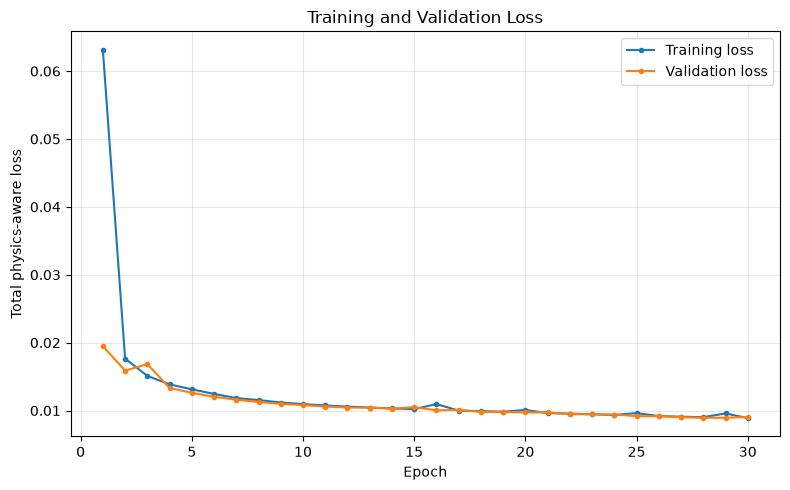

In [70]:
# ============================================================
# STEP 16A: PLOT TRAINING AND VALIDATION LOSS
# ============================================================

import pandas as pd

metrics_path = baseline_result[
    "metrics_csv_path"
]

metrics_df = pd.read_csv(
    metrics_path
)

# Lightning may write training and validation metrics on
# separate rows, so collect the non-empty value for each epoch.
train_loss_by_epoch = (
    metrics_df
    .dropna(subset=["train_loss"])
    .groupby("epoch")["train_loss"]
    .last()
)

val_loss_by_epoch = (
    metrics_df
    .dropna(subset=["val_loss"])
    .groupby("epoch")["val_loss"]
    .last()
)

# Lightning counts epochs from zero.
train_epochs = (
    train_loss_by_epoch.index.to_numpy()
    + 1
)

val_epochs = (
    val_loss_by_epoch.index.to_numpy()
    + 1
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    train_epochs,
    train_loss_by_epoch.to_numpy(),
    marker="o",
    markersize=3,
    label="Training loss"
)

plt.plot(
    val_epochs,
    val_loss_by_epoch.to_numpy(),
    marker="o",
    markersize=3,
    label="Validation loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Total physics-aware loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.legend()
plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "baseline_training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Reconstruction

In [71]:
# ------------------------------------------------
# EVALUATION SETTINGS
# ------------------------------------------------

EVAL_BATCH_SIZE = 1000
MAX_EVAL_BATCHES = 10     # still used for JZ evaluation
EVENT_INDEX = 20

FIGURE_DIR = "figures/baseline_32_latent_channels"

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)

model = model.to(device)
model.eval()

scale_gpu = scale_gpu.to(device)

print("Evaluation device:", device)
print("Figures will be saved in:", FIGURE_DIR)

print(
    "Number of held-out ggF validation events:",
    len(val_events_cpu)
)

print(
    "Maximum JZ events:",
    EVAL_BATCH_SIZE * MAX_EVAL_BATCHES
)

Evaluation device: cuda
Figures will be saved in: figures/baseline_32_latent_channels
Number of held-out ggF validation events: 9570
Maximum JZ events: 10000


In [72]:
# ------------------------------------------------
# INVERSE PREPROCESSING
# ------------------------------------------------

def inverse_preprocess_events_gpu(
    x_reco_scaled_gpu,
    scale_gpu
):
    """
    Converts:
        (N, 6, 50, 64) scaled log-space output
    back to:
        (N, 50, 64, 6) physical energies.
    """

    # Undo:
    # x_scaled = log(1 + E_T) / scale
    reco_energy_gpu = torch.expm1(
        x_reco_scaled_gpu * scale_gpu
    )

    # The decoder output is unbounded, so small negative
    # reconstructed physical energies are set to zero.
    reco_energy_gpu = torch.clamp(
        reco_energy_gpu,
        min=0.0
    )

    return reco_energy_gpu.permute(
        0, 2, 3, 1
    ).contiguous()

In [73]:
# ------------------------------------------------
# PATH-BASED RECONSTRUCTION
# Used for JZ
# ------------------------------------------------

def reconstruct_sample_gpu(
    path,
    model,
    scale_gpu,
    batch_size,
    max_batches
):
    """
    Returns:
        original_events_np:      (N, 50, 64, 6)
        reconstructed_events_np: (N, 50, 64, 6)
        event_mse_np:            MSE in scaled log space
    """

    model.eval()

    original_events = []
    reconstructed_events = []
    event_mse_values = []

    with torch.no_grad():

        for events_gpu in iter_gpu_event_batches(
            path,
            batch_size=batch_size,
            max_batches=max_batches
        ):

            # Same preprocessing used during training
            x_gpu = preprocess_events_gpu(
                events_gpu,
                scale_gpu
            )

            # Autoencoder reconstruction
            x_reco_scaled_gpu = model(
                x_gpu
            )

            # Reconstruction MSE in scaled log space
            event_mse_gpu = torch.mean(
                (x_reco_scaled_gpu - x_gpu) ** 2,
                dim=(1, 2, 3)
            )

            # Convert reconstruction back to physical E_T
            reco_events_gpu = inverse_preprocess_events_gpu(
                x_reco_scaled_gpu,
                scale_gpu
            )

            original_events.append(
                events_gpu.cpu().numpy()
            )

            reconstructed_events.append(
                reco_events_gpu.cpu().numpy()
            )

            event_mse_values.append(
                event_mse_gpu.cpu().numpy()
            )

    original_events_np = np.concatenate(
        original_events,
        axis=0
    )

    reconstructed_events_np = np.concatenate(
        reconstructed_events,
        axis=0
    )

    event_mse_np = np.concatenate(
        event_mse_values,
        axis=0
    )

    return (
        original_events_np,
        reconstructed_events_np,
        event_mse_np
    )

In [74]:
# ------------------------------------------------
# VALIDATION-SET RECONSTRUCTION
# Used for the held-out ggF validation events
# ------------------------------------------------

def reconstruct_validation_gpu(
    val_events_cpu,
    model,
    scale_gpu,
    batch_size=1000
):
    """
    Reconstructs ALL held-out validation events.

    Input:
        val_events_cpu:
            raw physical-energy events
            shape (N, 50, 64, 6)

    Returns:
        original_events_np:
            (N, 50, 64, 6)

        reconstructed_events_np:
            (N, 50, 64, 6)

        event_mse_np:
            per-event MSE in scaled log space
    """

    model.eval()

    validation_loader = DataLoader(
        TensorDataset(
            val_events_cpu
        ),
        batch_size=batch_size,
        shuffle=False,
        drop_last=False
    )

    original_events = []
    reconstructed_events = []
    event_mse_values = []

    with torch.no_grad():

        for batch in validation_loader:

            # TensorDataset returns a one-element tuple.
            # Move the raw physical-energy events to GPU.
            events_gpu = batch[0].to(
                device,
                non_blocking=True
            )

            x_gpu = preprocess_events_gpu(
                events_gpu,
                scale_gpu
            )

            # ------------------------------------------------
            # AUTOENCODER
            # ------------------------------------------------
            x_reco_scaled_gpu = model(
                x_gpu
            )

            # ------------------------------------------------
            # MSE IN THE SAME SCALED LOG SPACE
            # ------------------------------------------------
            event_mse_gpu = torch.mean(
                (x_reco_scaled_gpu - x_gpu) ** 2,
                dim=(1, 2, 3)
            )

            reco_events_gpu = inverse_preprocess_events_gpu(
                x_reco_scaled_gpu,
                scale_gpu
            )

            # Save raw originals and reconstructed physical energies
            original_events.append(
                events_gpu.cpu().numpy()
            )

            reconstructed_events.append(
                reco_events_gpu.cpu().numpy()
            )

            event_mse_values.append(
                event_mse_gpu.cpu().numpy()
            )

    original_events_np = np.concatenate(
        original_events,
        axis=0
    )

    reconstructed_events_np = np.concatenate(
        reconstructed_events,
        axis=0
    )

    event_mse_np = np.concatenate(
        event_mse_values,
        axis=0
    )

    return (
        original_events_np,
        reconstructed_events_np,
        event_mse_np
    )

In [75]:
# ------------------------------------------------
# ggF: HELD-OUT VALIDATION EVENTS
# ------------------------------------------------

ggf_original_sample, ggf_reco_sample, ggf_sample_mse = (
    reconstruct_validation_gpu(
        val_events_cpu=val_events_cpu,
        model=model,
        scale_gpu=scale_gpu,
        batch_size=EVAL_BATCH_SIZE
    )
)

print("\nggF validation evaluation")
print(
    "Original shape:",
    ggf_original_sample.shape
)
print(
    "Reconstructed shape:",
    ggf_reco_sample.shape
)
print(
    "Number of events:",
    len(ggf_sample_mse)
)
print(
    "Mean event MSE:",
    ggf_sample_mse.mean()
)


ggF validation evaluation
Original shape: (9570, 50, 64, 6)
Reconstructed shape: (9570, 50, 64, 6)
Number of events: 9570
Mean event MSE: 0.0017132862


In [76]:
# ------------------------------------------------
# JZ: UNSEEN BACKGROUND SAMPLE
# ------------------------------------------------

jz_original_sample, jz_reco_sample, jz_sample_mse = (
    reconstruct_sample_gpu(
        jz_path,
        model,
        scale_gpu,
        batch_size=EVAL_BATCH_SIZE,
        max_batches=MAX_EVAL_BATCHES
    )
)

print("\nJZ evaluation")
print(
    "Original shape:",
    jz_original_sample.shape
)
print(
    "Reconstructed shape:",
    jz_reco_sample.shape
)
print(
    "Number of events:",
    len(jz_sample_mse)
)
print(
    "Mean event MSE:",
    jz_sample_mse.mean()
)


JZ evaluation
Original shape: (10000, 50, 64, 6)
Reconstructed shape: (10000, 50, 64, 6)
Number of events: 10000
Mean event MSE: 0.0013854849


Event Energy Maps

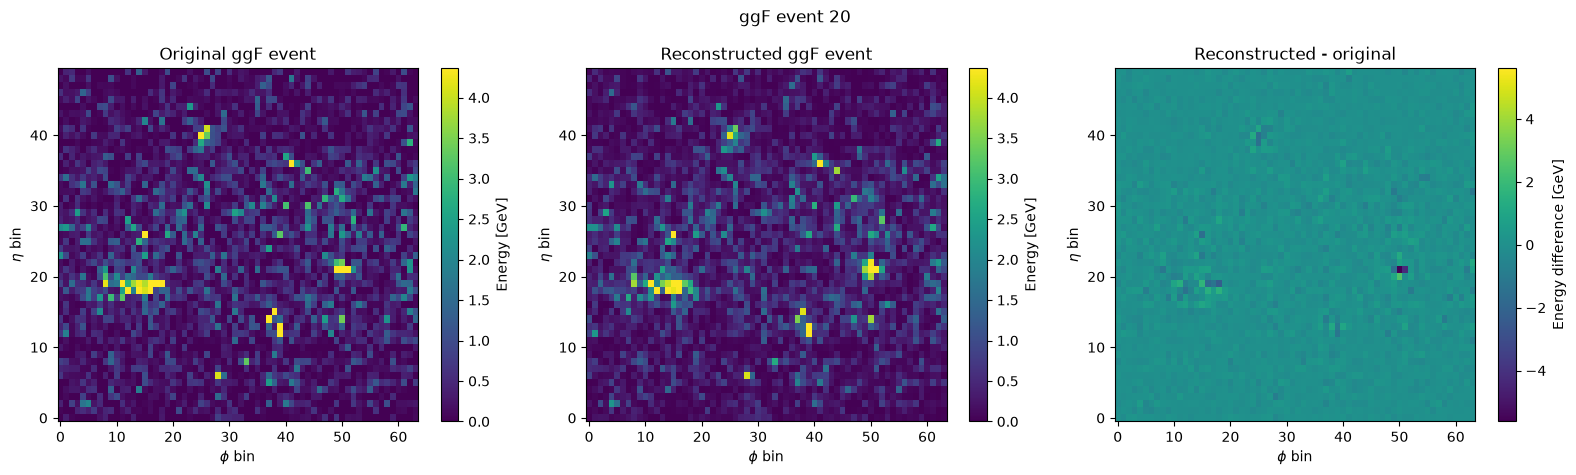

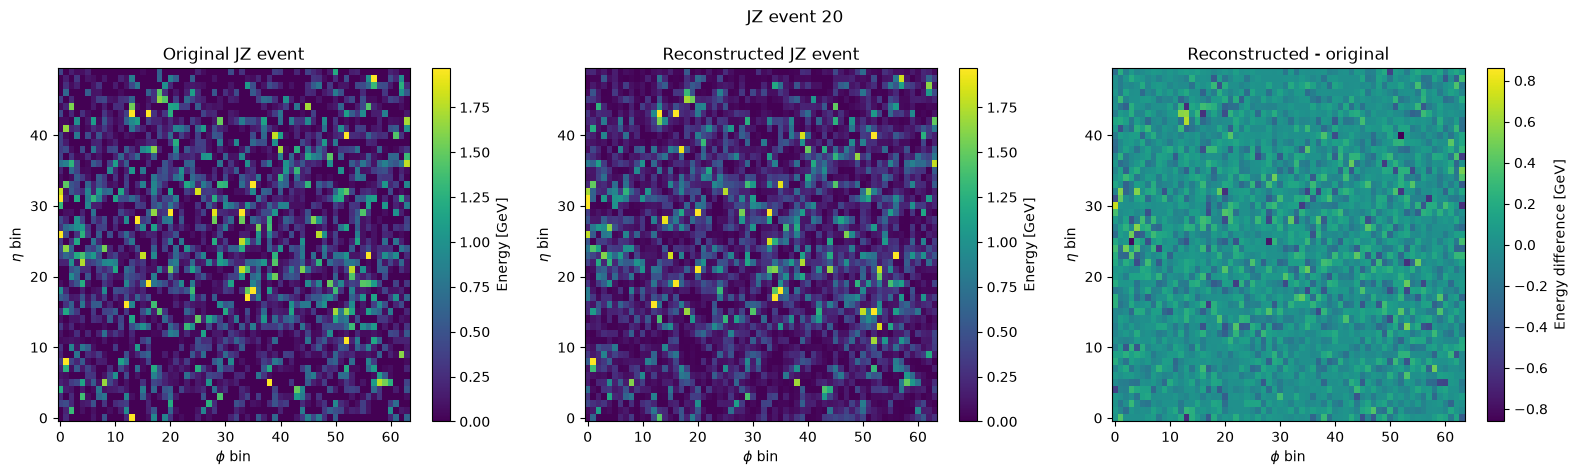

In [77]:
def plot_original_vs_reco_event(
    original_events,
    reconstructed_events,
    event_index,
    sample_name,
    save_path=None
):
    original_image = original_events[
        event_index
    ].sum(axis=-1)

    reconstructed_image = reconstructed_events[
        event_index
    ].sum(axis=-1)

    difference_image = (
        reconstructed_image
        - original_image
    )

    vmax = max(
        np.percentile(original_image, 99.5),
        np.percentile(reconstructed_image, 99.5)
    )

    if vmax <= 0:
        vmax = 1.0

    difference_limit = np.max(
        np.abs(difference_image)
    )

    if difference_limit <= 0:
        difference_limit = 1.0

    fig, axes = plt.subplots(
        1, 3, figsize=(16, 4.8)
    )

    im0 = axes[0].imshow(
        original_image,
        aspect="auto",
        origin="lower",
        vmin=0,
        vmax=vmax
    )

    axes[0].set_title(
        f"Original {sample_name} event"
    )

    axes[0].set_xlabel(r"$\phi$ bin")
    axes[0].set_ylabel(r"$\eta$ bin")

    fig.colorbar(
        im0,
        ax=axes[0],
        label="Energy [GeV]"
    )

    im1 = axes[1].imshow(
        reconstructed_image,
        aspect="auto",
        origin="lower",
        vmin=0,
        vmax=vmax
    )

    axes[1].set_title(
        f"Reconstructed {sample_name} event"
    )

    axes[1].set_xlabel(r"$\phi$ bin")
    axes[1].set_ylabel(r"$\eta$ bin")

    fig.colorbar(
        im1,
        ax=axes[1],
        label="Energy [GeV]"
    )

    im2 = axes[2].imshow(
        difference_image,
        aspect="auto",
        origin="lower",
        vmin=-difference_limit,
        vmax=difference_limit
    )

    axes[2].set_title(
        "Reconstructed - original"
    )

    axes[2].set_xlabel(r"$\phi$ bin")
    axes[2].set_ylabel(r"$\eta$ bin")

    fig.colorbar(
        im2,
        ax=axes[2],
        label="Energy difference [GeV]"
    )

    plt.suptitle(
        f"{sample_name} event {event_index}"
    )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=250,
            bbox_inches="tight"
        )

    plt.show()


plot_original_vs_reco_event(
    ggf_original_sample,
    ggf_reco_sample,
    event_index=EVENT_INDEX,
    sample_name="ggF",
    save_path=(
        f"{FIGURE_DIR}/"
        "ggf_event_original_vs_reconstructed.png"
    )
)

plot_original_vs_reco_event(
    jz_original_sample,
    jz_reco_sample,
    event_index=EVENT_INDEX,
    sample_name="JZ",
    save_path=(
        f"{FIGURE_DIR}/"
        "jz_event_original_vs_reconstructed.png"
    )
)

Average Energy Heat Maps

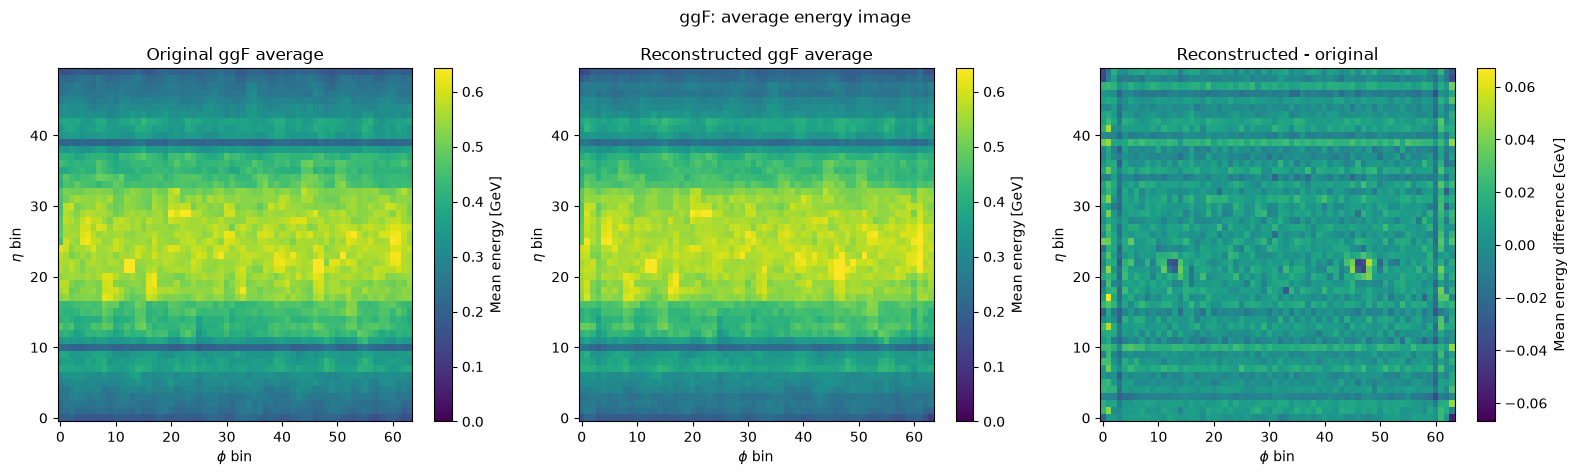

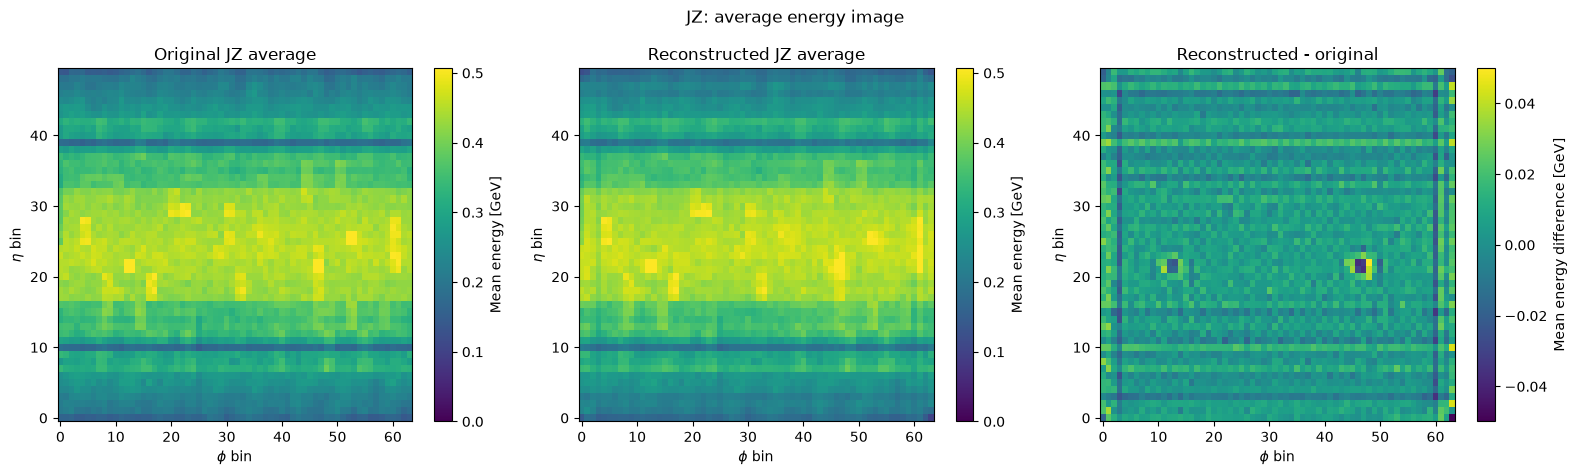

In [78]:
def plot_average_energy_image_comparison(
    original_events,
    reconstructed_events,
    sample_name,
    save_path=None
):
    original_average_image = (
        original_events
        .sum(axis=-1)
        .mean(axis=0)
    )

    reconstructed_average_image = (
        reconstructed_events
        .sum(axis=-1)
        .mean(axis=0)
    )

    difference_image = (
        reconstructed_average_image
        - original_average_image
    )

    vmax = max(
        np.percentile(
            original_average_image,
            99.5
        ),
        np.percentile(
            reconstructed_average_image,
            99.5
        )
    )

    if vmax <= 0:
        vmax = 1.0

    difference_limit = np.max(
        np.abs(difference_image)
    )

    if difference_limit <= 0:
        difference_limit = 1.0

    fig, axes = plt.subplots(
        1, 3, figsize=(16, 4.8)
    )

    im0 = axes[0].imshow(
        original_average_image,
        aspect="auto",
        origin="lower",
        vmin=0,
        vmax=vmax
    )

    axes[0].set_title(
        f"Original {sample_name} average"
    )

    axes[0].set_xlabel(r"$\phi$ bin")
    axes[0].set_ylabel(r"$\eta$ bin")

    fig.colorbar(
        im0,
        ax=axes[0],
        label="Mean energy [GeV]"
    )

    im1 = axes[1].imshow(
        reconstructed_average_image,
        aspect="auto",
        origin="lower",
        vmin=0,
        vmax=vmax
    )

    axes[1].set_title(
        f"Reconstructed {sample_name} average"
    )

    axes[1].set_xlabel(r"$\phi$ bin")
    axes[1].set_ylabel(r"$\eta$ bin")

    fig.colorbar(
        im1,
        ax=axes[1],
        label="Mean energy [GeV]"
    )

    im2 = axes[2].imshow(
        difference_image,
        aspect="auto",
        origin="lower",
        vmin=-difference_limit,
        vmax=difference_limit
    )

    axes[2].set_title(
        "Reconstructed - original"
    )

    axes[2].set_xlabel(r"$\phi$ bin")
    axes[2].set_ylabel(r"$\eta$ bin")

    fig.colorbar(
        im2,
        ax=axes[2],
        label="Mean energy difference [GeV]"
    )

    plt.suptitle(
        f"{sample_name}: average energy image"
    )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=250,
            bbox_inches="tight"
        )

    plt.show()


plot_average_energy_image_comparison(
    ggf_original_sample,
    ggf_reco_sample,
    sample_name="ggF",
    save_path=(
        f"{FIGURE_DIR}/"
        "ggf_average_energy_image.png"
    )
)

plot_average_energy_image_comparison(
    jz_original_sample,
    jz_reco_sample,
    sample_name="JZ",
    save_path=(
        f"{FIGURE_DIR}/"
        "jz_average_energy_image.png"
    )
)

Total Energy Reconstruction


ggF
Mean original total energy: 1298.1265
Mean reconstructed total energy: 1313.1454
Mean reconstructed/original ratio: 1.0117275
Median reconstructed/original ratio: 1.0126591


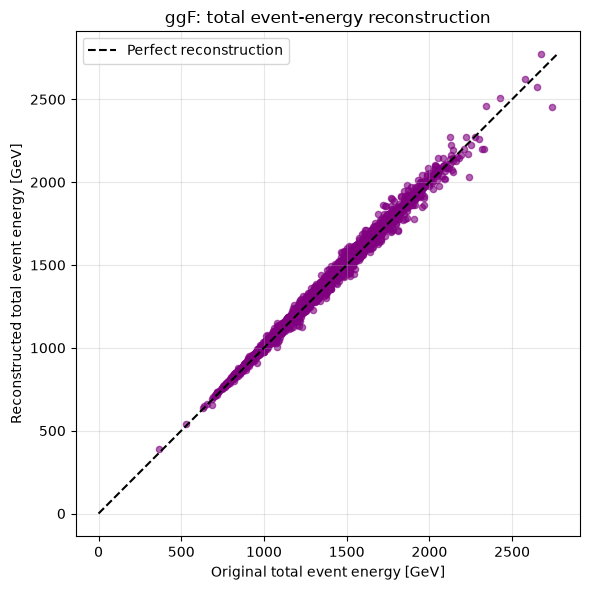


JZ
Mean original total energy: 1067.7
Mean reconstructed total energy: 1082.3816
Mean reconstructed/original ratio: 1.0137695
Median reconstructed/original ratio: 1.0137608


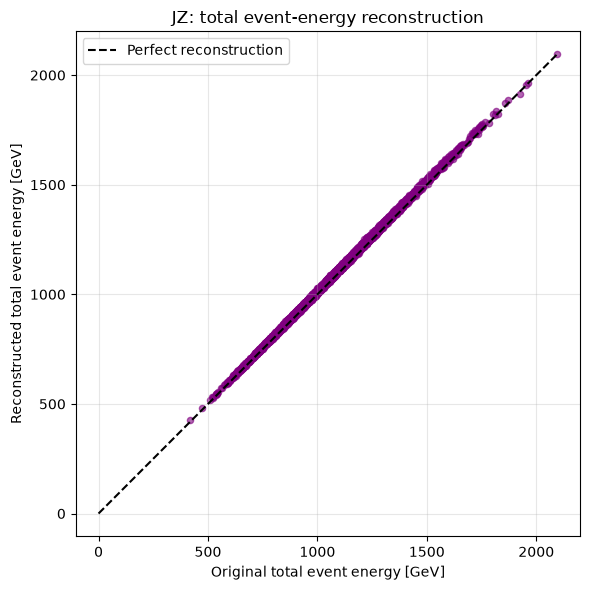

In [79]:
def plot_total_event_energy_comparison(
    original_events,
    reconstructed_events,
    sample_name,
    save_path=None
):
    original_total_energy = original_events.sum(
        axis=(1, 2, 3)
    )

    reconstructed_total_energy = reconstructed_events.sum(
        axis=(1, 2, 3)
    )

    energy_ratio = (
        reconstructed_total_energy
        / np.maximum(
            original_total_energy,
            1e-8
        )
    )

    print(f"\n{sample_name}")
    print(
        "Mean original total energy:",
        original_total_energy.mean()
    )
    print(
        "Mean reconstructed total energy:",
        reconstructed_total_energy.mean()
    )
    print(
        "Mean reconstructed/original ratio:",
        energy_ratio.mean()
    )
    print(
        "Median reconstructed/original ratio:",
        np.median(energy_ratio)
    )

    max_energy = max(
        original_total_energy.max(),
        reconstructed_total_energy.max()
    )

    plt.figure(figsize=(6, 6))

    plt.scatter(
        original_total_energy,
        reconstructed_total_energy,
        alpha=0.6,
        s=20,
        color = 'purple'
    )

    plt.plot(
        [0, max_energy],
        [0, max_energy],
        linestyle="--",
        label="Perfect reconstruction",
        color = 'black'
    )

    plt.xlabel(
        "Original total event energy [GeV]"
    )

    plt.ylabel(
        "Reconstructed total event energy [GeV]"
    )

    plt.title(
        f"{sample_name}: total event-energy reconstruction"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=250,
            bbox_inches="tight"
        )

    plt.show()

    return (
        original_total_energy,
        reconstructed_total_energy,
        energy_ratio
    )


(
    ggf_original_total_energy,
    ggf_reco_total_energy,
    ggf_energy_ratio
) = plot_total_event_energy_comparison(
    ggf_original_sample,
    ggf_reco_sample,
    sample_name="ggF",
    save_path=(
        f"{FIGURE_DIR}/"
        "ggf_total_event_energy_reconstruction.png"
    )
)

(
    jz_original_total_energy,
    jz_reco_total_energy,
    jz_energy_ratio
) = plot_total_event_energy_comparison(
    jz_original_sample,
    jz_reco_sample,
    sample_name="JZ",
    save_path=(
        f"{FIGURE_DIR}/"
        "jz_total_event_energy_reconstruction.png"
    )
)

Total Energy Error


ggF energy error
Mean relative energy error: 0.011727384
Median relative energy error: 0.012659013
Mean absolute relative energy error: 0.013936781


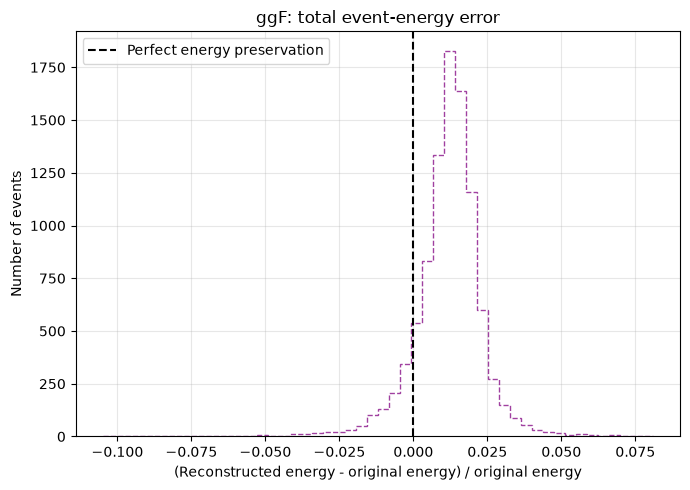


JZ energy error
Mean relative energy error: 0.01376951
Median relative energy error: 0.013760865
Mean absolute relative energy error: 0.013772895


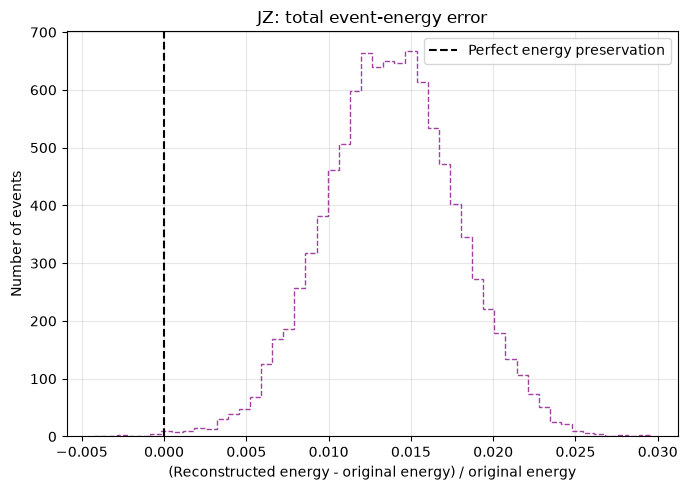

In [80]:
def plot_total_event_energy_error(
    energy_ratio,
    sample_name,
    save_path=None
):
    relative_energy_error = (
        energy_ratio - 1.0
    )

    print(f"\n{sample_name} energy error")
    print(
        "Mean relative energy error:",
        relative_energy_error.mean()
    )
    print(
        "Median relative energy error:",
        np.median(relative_energy_error)
    )
    print(
        "Mean absolute relative energy error:",
        np.mean(
            np.abs(relative_energy_error)
        )
    )

    plt.figure(figsize=(7, 5))

    plt.hist(
        relative_energy_error,
        bins=50,
        alpha=0.75,
        color = 'purple',
        histtype= 'step',
        linestyle= '--'
    )

    plt.axvline(
        0.0,
        linestyle="--",
        label="Perfect energy preservation",
        color = 'black'
    )

    plt.xlabel(
        "(Reconstructed energy - original energy) / original energy"
    )

    plt.ylabel(
        "Number of events"
    )

    plt.title(
        f"{sample_name}: total event-energy error"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=250,
            bbox_inches="tight"
        )

    plt.show()

    return relative_energy_error


ggf_relative_energy_error = (
    plot_total_event_energy_error(
        ggf_energy_ratio,
        sample_name="ggF",
        save_path=(
            f"{FIGURE_DIR}/"
            "ggf_total_event_energy_error.png"
        )
    )
)

jz_relative_energy_error = (
    plot_total_event_energy_error(
        jz_energy_ratio,
        sample_name="JZ",
        save_path=(
            f"{FIGURE_DIR}/"
            "jz_total_event_energy_error.png"
        )
    )
)

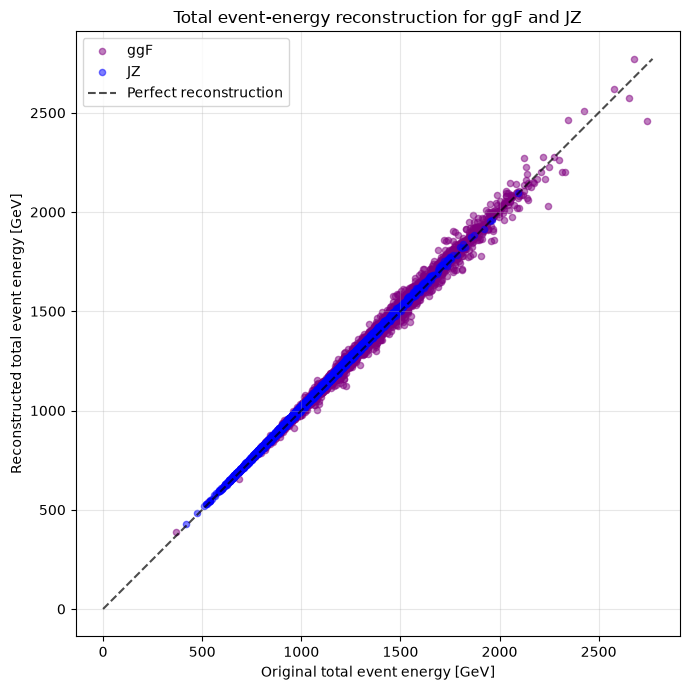

In [81]:
# Total event energy for each event
ggf_original_total_energy = ggf_original_sample.sum(axis=(1, 2, 3))
ggf_reco_total_energy = ggf_reco_sample.sum(axis=(1, 2, 3))

jz_original_total_energy = jz_original_sample.sum(axis=(1, 2, 3))
jz_reco_total_energy = jz_reco_sample.sum(axis=(1, 2, 3))


# Common axis range
max_energy = max(
    ggf_original_total_energy.max(),
    ggf_reco_total_energy.max(),
    jz_original_total_energy.max(),
    jz_reco_total_energy.max()
)


plt.figure(figsize=(7, 7))

plt.scatter(
    ggf_original_total_energy,
    ggf_reco_total_energy,
    alpha=0.5,
    s=20,
    label="ggF",
    color = 'purple'
)

plt.scatter(
    jz_original_total_energy,
    jz_reco_total_energy,
    alpha=0.5,
    s=20,
    label="JZ",
    color = 'blue'
)

plt.plot(
    [0, max_energy],
    [0, max_energy],
    linestyle="--",
    label="Perfect reconstruction",
    color = 'black',
    alpha = 0.7
)

plt.xlabel("Original total event energy [GeV]")
plt.ylabel("Reconstructed total event energy [GeV]")

plt.title(
    "Total event-energy reconstruction for ggF and JZ"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{FIGURE_DIR}/ggf_jz_total_event_energy_reconstruction.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

In [82]:
def print_image_metrics(original, reconstructed, sample_name):
    difference = reconstructed - original

    mae = np.mean(np.abs(difference))
    rmse = np.sqrt(np.mean(difference**2))

    nrmse = rmse / np.sqrt(
        np.mean(original**2)
    )

    print(sample_name)
    print(f"Image MAE:   {mae:.6f} GeV")
    print(f"Image RMSE:  {rmse:.6f} GeV")
    print(f"Image NRMSE: {100 * nrmse:.3f}%")
    print()


print_image_metrics(
    ggf_original_sample,
    ggf_reco_sample,
    "ggF"
)

print_image_metrics(
    jz_original_sample,
    jz_reco_sample,
    "JZ"
)

ggF
Image MAE:   0.047043 GeV
Image RMSE:  0.174288 GeV
Image NRMSE: 42.996%

JZ
Image MAE:   0.040108 GeV
Image RMSE:  0.086614 GeV
Image NRMSE: 47.634%



In [83]:
def print_active_cell_metrics(original, reconstructed, sample_name, threshold=2.0):
    mask = original > threshold

    difference = reconstructed[mask] - original[mask]

    mae = np.mean(np.abs(difference))
    rmse = np.sqrt(np.mean(difference**2))
    relative_mae = np.mean(
        np.abs(difference) / original[mask]
    )

    print(sample_name)
    print("Number of active cells:", np.sum(mask))
    print(f"Active-cell MAE: {mae:.4f} GeV")
    print(f"Active-cell RMSE: {rmse:.4f} GeV")
    print(f"Mean absolute relative error: {100 * relative_mae:.2f}%")
    print()


print_active_cell_metrics(
    ggf_original_sample,
    ggf_reco_sample,
    "ggF"
)

print_active_cell_metrics(
    jz_original_sample,
    jz_reco_sample,
    "JZ"
)

ggF
Number of active cells: 311820
Active-cell MAE: 1.7499 GeV
Active-cell RMSE: 3.5163 GeV
Mean absolute relative error: 34.08%

JZ
Number of active cells: 96356
Active-cell MAE: 0.8430 GeV
Active-cell RMSE: 1.0372 GeV
Mean absolute relative error: 30.96%



JET RECONSTURCTION

In [84]:
import vector

vector.register_awkward()



teting

In [85]:

# CONVERT IMAGES TO VECTORS ONE EVENT AT A TIME

 
def image_to_vectors(X, sum_layers=False):
    """
    Converts calorimeter images into four-vectors one event at a time.
 
    Input shape:
        (N, 50, 64, 6)
 
    sum_layers=False  ->  yields (50, 64, 6): one four-vector per CELL
    sum_layers=True   ->  yields (50, 64):    one four-vector per TOWER
                          (the six calorimeter layers are summed first)
    """
 
    if torch.is_tensor(X):
        X = X.detach().cpu().numpy()
 
    X = np.asarray(X, dtype=np.float32)
 
    if X.ndim != 4 or X.shape[1:] != (50, 64, 6):
        raise ValueError(
            "Expected X with shape (N, 50, 64, 6), "
            f"but received {X.shape}"
        )
 
    if sum_layers:
        # Sum the six calorimeter layers at each (eta, phi) position.
        X = X.sum(axis=3)          # (N, 50, 64)
        grid = (50, 64)
    else:
        grid = (50, 64, 6)
 
    idxs = np.indices(grid, dtype=np.float32)
 
    eta = (idxs[0] - np.median(idxs[0])) * 0.1
    phi = (idxs[1] - np.median(idxs[1])) * np.pi / 32
    mass = np.zeros(grid, dtype=np.float32)
 
    for event_index in range(len(X)):
        yield vector.arr(
            {
                "eta": eta,
                "phi": phi,
                "pt": X[event_index],
                "m": mass,
            }
        )
 
 

original

In [86]:
# ============================================================
# VECTORISATION
# ============================================================

jz_original_vectors = image_to_vectors(
    jz_original_sample
)

jz_reco_vectors = image_to_vectors(
    jz_reco_sample
)

ggf_original_vectors = image_to_vectors(
    ggf_original_sample
)

ggf_reco_vectors = image_to_vectors(
    ggf_reco_sample
)

print(
    "JZ original events:",
    len(jz_original_sample)
)

print(
    "JZ reconstructed events:",
    len(jz_reco_sample)
)

print(
    "ggF original events:",
    len(ggf_original_sample)
)

print(
    "ggF reconstructed events:",
    len(ggf_reco_sample)
)

JZ original events: 10000
JZ reconstructed events: 10000
ggF original events: 9570
ggF reconstructed events: 9570


In [87]:
# converting vectors to jets

def antikt_jets(vectors, min_pt, r=0.4):
    jetdef = fastjet.JetDefinition(fastjet.antikt_algorithm, r)
    cluster = fastjet.ClusterSequence(vectors, jetdef)
    return cluster.inclusive_jets(min_pt)

testing

In [88]:

#  CLUSTERING

def cluster_events(
    vector_data,
    n_events=None,
    energy_threshold=0.0,
    jet_min_pt=0.0,
    r=0.4
):
    """
    Flattens each event into a list of four-vectors, applies the energy
    threshold and reconstructs anti-kT jets.
 
    The threshold acts on whatever image_to_vectors produced: per cell if
    sum_layers=False, per summed tower if sum_layers=True.
    """
 
    jets_per_event = []
 
    for event_index, event_vectors in enumerate(vector_data):
 
        if n_events is not None and event_index >= n_events:
            break
 
        event_vectors = event_vectors.reshape(-1)
 
        event_vectors = event_vectors[
            event_vectors.pt > energy_threshold
        ]
 
        if len(event_vectors) == 0:
            jets_per_event.append([])
            continue
 
        event_vectors_ak = ak.zip(
            {
                "pt": event_vectors.pt,
                "eta": event_vectors.eta,
                "phi": event_vectors.phi,
                "mass": event_vectors.mass,
            },
            with_name="Momentum4D"
        )
 
        jets = antikt_jets(
            event_vectors_ak,
            min_pt=jet_min_pt,
            r=r
        )
 
        jets_per_event.append(jets)
 
    return jets_per_event

In [89]:
#TOWER_THRESHOLD = 2.0

#JET_MIN_PT = 10.0
#JET_RADIUS = 0.4
#MATCHING_MAX_DR = 0.3

n_jz_events = min(
    len(jz_original_sample),
    len(jz_reco_sample)
)

n_ggf_events = min(
    len(ggf_original_sample),
    len(ggf_reco_sample)
)

print(
    "Number of JZ events:",
    n_jz_events
)

print(
    "Number of ggF events:",
    n_ggf_events
)


Number of JZ events: 10000
Number of ggF events: 9570


In [90]:
#new cluster
ENERGY_THRESHOLD = 2.0
JET_MIN_PT = 10.0
JET_RADIUS = 0.4
MATCHING_MAX_DR = 0.3
 
SUM_LAYERS = True     # True = tower thresholding, False = cell thresholding
 
n_ggf_events = min(len(ggf_original_sample), len(ggf_reco_sample))
n_jz_events = min(len(jz_original_sample), len(jz_reco_sample))
 
# Rebuild the vectors each time
ggf_original_jets = cluster_events(
    image_to_vectors(ggf_original_sample, sum_layers=SUM_LAYERS),
    n_events=n_ggf_events,
    energy_threshold=ENERGY_THRESHOLD,
    jet_min_pt=JET_MIN_PT,
    r=JET_RADIUS
)
 
ggf_reco_jets = cluster_events(
    image_to_vectors(ggf_reco_sample, sum_layers=SUM_LAYERS),
    n_events=n_ggf_events,
    energy_threshold=ENERGY_THRESHOLD,
    jet_min_pt=JET_MIN_PT,
    r=JET_RADIUS
)
 
jz_original_jets = cluster_events(
    image_to_vectors(jz_original_sample, sum_layers=SUM_LAYERS),
    n_events=n_jz_events,
    energy_threshold=ENERGY_THRESHOLD,
    jet_min_pt=JET_MIN_PT,
    r=JET_RADIUS
)
 
jz_reco_jets = cluster_events(
    image_to_vectors(jz_reco_sample, sum_layers=SUM_LAYERS),
    n_events=n_jz_events,
    energy_threshold=ENERGY_THRESHOLD,
    jet_min_pt=JET_MIN_PT,
    r=JET_RADIUS
)
 

In [91]:
#data summary

def jet_count_summary(jets_per_event, label):
    counts = np.array(
        [len(jets) for jets in jets_per_event]
    )

    print(label)
    print("Mean jets per event:", counts.mean())
    print("Median jets per event:", np.median(counts))
    print("Minimum jets:", counts.min())
    print("Maximum jets:", counts.max())
    print()


def leading_jet_pt_summary(jets_per_event, label):
    leading_pts = []

    for jets in jets_per_event:

        if len(jets) == 0:
            leading_pts.append(np.nan)
        else:
            leading_pts.append(
                np.max(
                    ak.to_numpy(jets.pt)
                )
            )

    leading_pts = np.array(
        leading_pts
    )

    print(label)
    print(
        "Mean leading jet pT:",
        np.nanmean(leading_pts)
    )
    print(
        "Median leading jet pT:",
        np.nanmedian(leading_pts)
    )
    print(
        "Minimum leading jet pT:",
        np.nanmin(leading_pts)
    )
    print(
        "Maximum leading jet pT:",
        np.nanmax(leading_pts)
    )
    print()


jet_count_summary(
    jz_original_jets,
    "JZ original jets"
)

jet_count_summary(
    jz_reco_jets,
    "JZ reconstructed jets"
)

jet_count_summary(
    ggf_original_jets,
    "ggF original jets"
)

jet_count_summary(
    ggf_reco_jets,
    "ggF reconstructed jets"
)

leading_jet_pt_summary(
    jz_original_jets,
    "JZ original leading jets"
)

leading_jet_pt_summary(
    jz_reco_jets,
    "JZ reconstructed leading jets"
)

leading_jet_pt_summary(
    ggf_original_jets,
    "ggF original leading jets"
)

leading_jet_pt_summary(
    ggf_reco_jets,
    "ggF reconstructed leading jets"
)

JZ original jets
Mean jets per event: 1.2249
Median jets per event: 1.0
Minimum jets: 0
Maximum jets: 15

JZ reconstructed jets
Mean jets per event: 0.7837
Median jets per event: 0.0
Minimum jets: 0
Maximum jets: 11

ggF original jets
Mean jets per event: 4.855590386624869
Median jets per event: 5.0
Minimum jets: 0
Maximum jets: 15

ggF reconstructed jets
Mean jets per event: 4.276384535005224
Median jets per event: 4.0
Minimum jets: 0
Maximum jets: 14

JZ original leading jets
Mean leading jet pT: 15.785872808288941
Median leading jet pT: 13.737750213189008
Minimum leading jet pT: 10.0000948267845
Maximum leading jet pT: 121.16124205202446

JZ reconstructed leading jets
Mean leading jet pT: 15.600917348470484
Median leading jet pT: 13.407649991554008
Minimum leading jet pT: 10.000835187509448
Maximum leading jet pT: 117.19473907610849

ggF original leading jets
Mean leading jet pT: 88.96148075569147
Median leading jet pT: 77.89685650582899
Minimum leading jet pT: 10.300309184185615
Ma

In [92]:
from scipy.optimize import linear_sum_assignment
import os

os.makedirs(FIGURE_DIR, exist_ok=True)

Average Tower Multiplicity v/s p_T

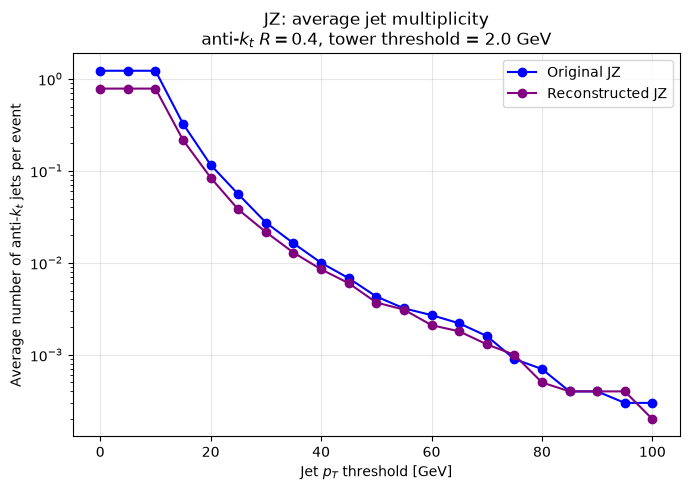

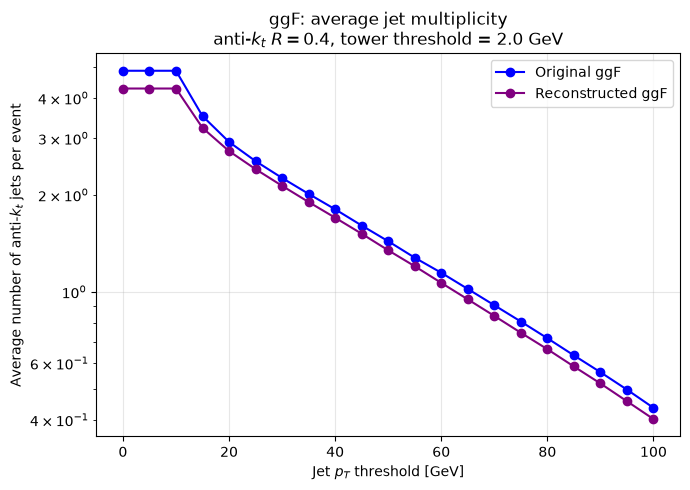

In [93]:
def get_jet_pts(jets):

    if len(jets) == 0:
        return np.array([])

    return ak.to_numpy(
        jets.pt
    )


def average_njets_vs_pt_threshold(
    jets_per_event,
    pt_thresholds
):
    mean_njets = []

    for pt_threshold in pt_thresholds:

        counts = []

        for jets in jets_per_event:

            jet_pts = get_jet_pts(
                jets
            )

            counts.append(
                np.sum(
                    jet_pts > pt_threshold
                )
            )

        mean_njets.append(
            np.mean(counts)
        )

    return np.array(
        mean_njets
    )


def plot_average_jet_multiplicity(
    original_jets,
    reconstructed_jets,
    sample_name,
    save_path=None
):
    pt_thresholds = np.arange(
        0,
        105,
        5
    )

    original_mean_njets = (
        average_njets_vs_pt_threshold(
            original_jets,
            pt_thresholds
        )
    )

    reconstructed_mean_njets = (
        average_njets_vs_pt_threshold(
            reconstructed_jets,
            pt_thresholds
        )
    )

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        pt_thresholds,
        np.where(
            original_mean_njets > 0,
            original_mean_njets,
            np.nan
        ),
        marker="o",
        label=f"Original {sample_name}",
        color = 'blue'
    )

    plt.plot(
        pt_thresholds,
        np.where(
            reconstructed_mean_njets > 0,
            reconstructed_mean_njets,
            np.nan
        ),
        marker="o",
        label=f"Reconstructed {sample_name}",
        color = 'purple'
    )
    plt.yscale('log')
    plt.xlabel(
        r"Jet $p_T$ threshold [GeV]"
    )

    plt.ylabel(
        r"Average number of anti-$k_t$ jets per event"
    )

    plt.title(
        rf"{sample_name}: average jet multiplicity"
        "\n"
        rf"anti-$k_t$ $R={JET_RADIUS}$, "
        rf"tower threshold = {ENERGY_THRESHOLD} GeV"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=250,
            bbox_inches="tight"
        )

    plt.show()

    return (
        pt_thresholds,
        original_mean_njets,
        reconstructed_mean_njets
    )


(
    jz_pt_thresholds,
    jz_original_mean_njets,
    jz_reco_mean_njets
) = plot_average_jet_multiplicity(
    jz_original_jets,
    jz_reco_jets,
    sample_name="JZ",
    save_path=(
        f"{FIGURE_DIR}/"
        "jz_average_jet_multiplicity_original_vs_reco.png"
    )
)

(
    ggf_pt_thresholds,
    ggf_original_mean_njets,
    ggf_reco_mean_njets
) = plot_average_jet_multiplicity(
    ggf_original_jets,
    ggf_reco_jets,
    sample_name="ggF",
    save_path=(
        f"{FIGURE_DIR}/"
        "ggf_average_jet_multiplicity_original_vs_reco.png"
    )
)

helper functions

In [94]:

def match_jets_by_delta_r(
    original_jets,
    reconstructed_jets,
    max_dr=0.3
):
    """
    Matches the closest available original-reconstructed
    jet pair, considering only pairs with Delta R below max_dr.

    Each original jet and each reconstructed jet can be used once.
    """

    if (
        len(original_jets) == 0
        or len(reconstructed_jets) == 0
    ):
        return (
            np.array([], dtype=int),
            np.array([], dtype=int),
            np.array([])
        )

    original_eta = ak.to_numpy(
        original_jets.eta
    )

    original_phi = ak.to_numpy(
        original_jets.phi
    )

    reconstructed_eta = ak.to_numpy(
        reconstructed_jets.eta
    )

    reconstructed_phi = ak.to_numpy(
        reconstructed_jets.phi
    )

    deta = (
        original_eta[:, None]
        - reconstructed_eta[None, :]
    )

    dphi = np.arctan2(
        np.sin(
            original_phi[:, None]
            - reconstructed_phi[None, :]
        ),
        np.cos(
            original_phi[:, None]
            - reconstructed_phi[None, :]
        )
    )

    dr_matrix = np.sqrt(
        deta**2 + dphi**2
    )

    candidate_original, candidate_reconstructed = np.where(
        dr_matrix < max_dr
    )

    if len(candidate_original) == 0:
        return (
            np.array([], dtype=int),
            np.array([], dtype=int),
            np.array([])
        )

    candidate_dr = dr_matrix[
        candidate_original,
        candidate_reconstructed
    ]

    candidate_order = np.argsort(
        candidate_dr
    )

    used_original = set()
    used_reconstructed = set()

    matched_original = []
    matched_reconstructed = []
    matched_dr = []

    for candidate_index in candidate_order:

        original_index = candidate_original[
            candidate_index
        ]

        reconstructed_index = candidate_reconstructed[
            candidate_index
        ]

        if original_index in used_original:
            continue

        if reconstructed_index in used_reconstructed:
            continue

        matched_original.append(
            original_index
        )

        matched_reconstructed.append(
            reconstructed_index
        )

        matched_dr.append(
            candidate_dr[candidate_index]
        )

        used_original.add(
            original_index
        )

        used_reconstructed.add(
            reconstructed_index
        )

    return (
        np.array(
            matched_original,
            dtype=int
        ),
        np.array(
            matched_reconstructed,
            dtype=int
        ),
        np.array(
            matched_dr
        )
    )


def collect_matched_jet_pts(
    original_jets_per_event,
    reconstructed_jets_per_event,
    original_pt_min=10.0,
    max_dr=0.3
):
    """
    Applies the original-jet pT cut before matching and calculates
    the matching efficiency relative to all original jets passing
    that cut.
    """

    matched_original_pts = []
    matched_reco_pts = []
    matched_delta_rs = []

    total_original_jets_above_cut = 0
    total_matched_jets = 0

    for original_jets, reconstructed_jets in zip(
        original_jets_per_event,
        reconstructed_jets_per_event
    ):

        if len(original_jets) == 0:
            continue

        original_pts_all = ak.to_numpy(
            original_jets.pt
        )

        original_mask = (
            original_pts_all >= original_pt_min
        )

        selected_original_jets = original_jets[
            original_mask
        ]

        total_original_jets_above_cut += len(
            selected_original_jets
        )

        if (
            len(selected_original_jets) == 0
            or len(reconstructed_jets) == 0
        ):
            continue

        (
            original_indices,
            reconstructed_indices,
            matched_dr
        ) = match_jets_by_delta_r(
            selected_original_jets,
            reconstructed_jets,
            max_dr=max_dr
        )

        if len(original_indices) == 0:
            continue

        original_pts = ak.to_numpy(
            selected_original_jets.pt
        )[original_indices]

        reconstructed_pts = ak.to_numpy(
            reconstructed_jets.pt
        )[reconstructed_indices]

        matched_original_pts.extend(
            original_pts
        )

        matched_reco_pts.extend(
            reconstructed_pts
        )

        matched_delta_rs.extend(
            matched_dr
        )

        total_matched_jets += len(
            original_indices
        )

    matched_original_pts = np.array(
        matched_original_pts
    )

    matched_reco_pts = np.array(
        matched_reco_pts
    )

    matched_delta_rs = np.array(
        matched_delta_rs
    )

    if total_original_jets_above_cut == 0:
        matching_efficiency = np.nan
    else:
        matching_efficiency = (
            total_matched_jets
            / total_original_jets_above_cut
        )

    return (
        matched_original_pts,
        matched_reco_pts,
        matched_delta_rs,
        matching_efficiency
    )


Original v/s Recon p_T by delta R matching

JZ
Number of matched jets: 6437
Matching efficiency: 0.525512286717283


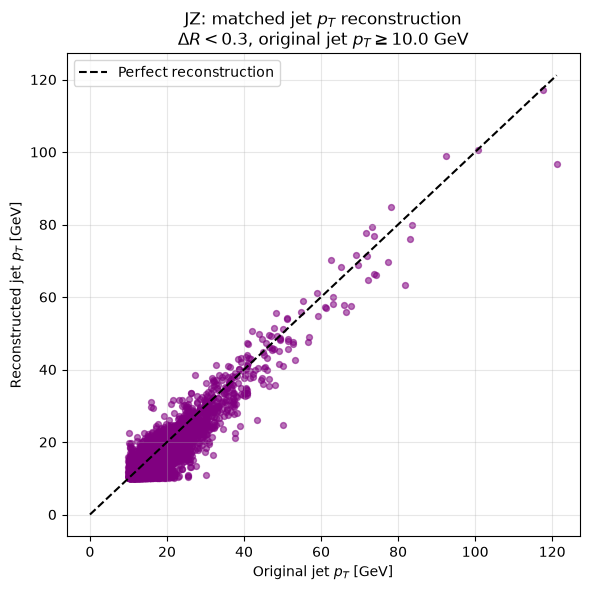

ggF
Number of matched jets: 39009
Matching efficiency: 0.8394809331152621


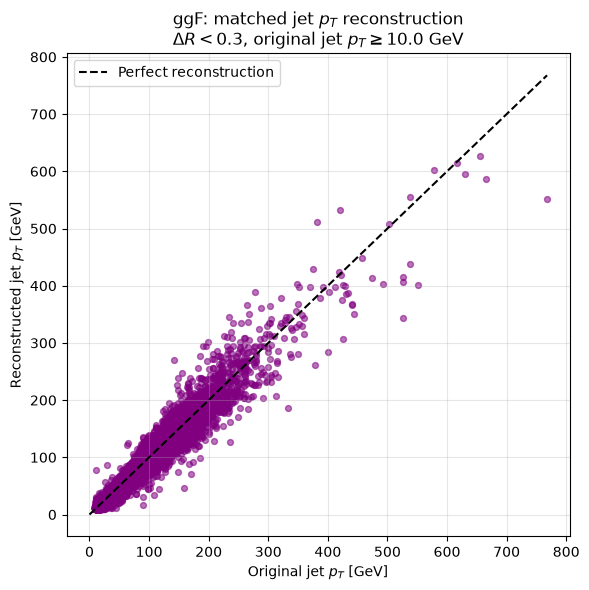

In [95]:
def plot_matched_jet_pt_scatter(
    original_jets,
    reconstructed_jets,
    sample_name,
    original_pt_min,
    max_dr,
    save_path=None
):
    (
        matched_original_pts,
        matched_reco_pts,
        matched_delta_rs,
        matching_efficiency
    ) = collect_matched_jet_pts(
        original_jets,
        reconstructed_jets,
        original_pt_min=original_pt_min,
        max_dr=max_dr
    )

    print(sample_name)
    print(
        "Number of matched jets:",
        len(matched_original_pts)
    )
    print(
        "Matching efficiency:",
        matching_efficiency
    )

    if len(matched_original_pts) == 0:
        print("No matched jets found.")

        return (
            matched_original_pts,
            matched_reco_pts,
            matched_delta_rs,
            matching_efficiency
        )

    max_pt = max(
        matched_original_pts.max(),
        matched_reco_pts.max()
    )

    plt.figure(
        figsize=(6, 6)
    )

    plt.scatter(
        matched_original_pts,
        matched_reco_pts,
        alpha=0.55,
        s=18,
        color = 'purple'
    )

    plt.plot(
        [0, max_pt],
        [0, max_pt],
        linestyle="--",
        label="Perfect reconstruction",
        color = 'black'
    )

    plt.xlabel(
        r"Original jet $p_T$ [GeV]"
    )

    plt.ylabel(
        r"Reconstructed jet $p_T$ [GeV]"
    )

    plt.title(
        rf"{sample_name}: matched jet $p_T$ reconstruction"
        "\n"
        rf"$\Delta R < {max_dr}$, "
        rf"original jet $p_T \geq {original_pt_min}$ GeV"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=250,
            bbox_inches="tight"
        )

    plt.show()

    return (
        matched_original_pts,
        matched_reco_pts,
        matched_delta_rs,
        matching_efficiency
    )


(
    jz_matched_original_pts,
    jz_matched_reco_pts,
    jz_matched_dr,
    jz_matching_efficiency
) = plot_matched_jet_pt_scatter(
    jz_original_jets,
    jz_reco_jets,
    sample_name="JZ",
    original_pt_min=JET_MIN_PT,
    max_dr=MATCHING_MAX_DR,
    save_path=(
        f"{FIGURE_DIR}/"
        "jz_matched_jet_pt_original_vs_reco.png"
    )
)

(
    ggf_matched_original_pts,
    ggf_matched_reco_pts,
    ggf_matched_dr,
    ggf_matching_efficiency
) = plot_matched_jet_pt_scatter(
    ggf_original_jets,
    ggf_reco_jets,
    sample_name="ggF",
    original_pt_min=JET_MIN_PT,
    max_dr=MATCHING_MAX_DR,
    save_path=(
        f"{FIGURE_DIR}/"
        "ggf_matched_jet_pt_original_vs_reco.png"
    )
)

JZ
Mean relative pT residual: -0.06548798998267304
Median relative pT residual: -0.07405176259128758
Std relative pT residual: 0.16558679113729755


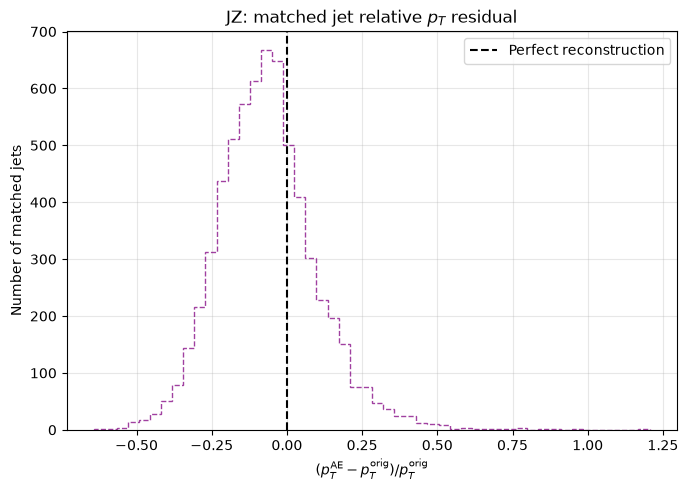

ggF
Mean relative pT residual: -0.05885485299928454
Median relative pT residual: -0.06310341792987685
Std relative pT residual: 0.14829176529120755


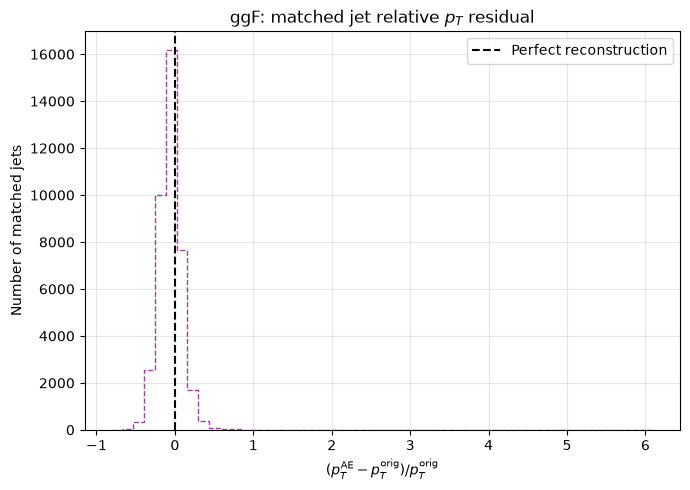

In [96]:
def plot_relative_pt_residual(
    matched_original_pts,
    matched_reco_pts,
    sample_name,
    save_path=None
):
    if len(matched_original_pts) == 0:
        print(f"No matched jets available for {sample_name}.")
        return None

    relative_pt_residual = (
        matched_reco_pts - matched_original_pts
    ) / matched_original_pts

    print(sample_name)
    print("Mean relative pT residual:", np.mean(relative_pt_residual))
    print("Median relative pT residual:", np.median(relative_pt_residual))
    print("Std relative pT residual:", np.std(relative_pt_residual))

    plt.figure(figsize=(7, 5))

    plt.hist(
        relative_pt_residual,
        bins=50,
        alpha=0.75,
        color = 'purple',
        histtype = 'step',
        linestyle = '--'
    )

    plt.axvline(
        0.0,
        linestyle="--",
        label="Perfect reconstruction",
        color = 'black'
    )

    plt.xlabel(
        r"$(p_T^{\mathrm{AE}} - p_T^{\mathrm{orig}}) / p_T^{\mathrm{orig}}$"
    )

    plt.ylabel("Number of matched jets")

    plt.title(
        rf"{sample_name}: matched jet relative $p_T$ residual"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=250, bbox_inches="tight")

    plt.show()

    return relative_pt_residual

jz_relative_pt_residual = plot_relative_pt_residual(
    jz_matched_original_pts,
    jz_matched_reco_pts,
    sample_name="JZ",
    save_path=f"{FIGURE_DIR}/jz_matched_jet_relative_pt_residual.png"
)
ggf_relative_pt_residual = plot_relative_pt_residual(
    ggf_matched_original_pts,
    ggf_matched_reco_pts,
    sample_name="ggF",
    save_path=f"{FIGURE_DIR}/ggf_matched_jet_relative_pt_residual.png"
)

In [97]:
relative_pt_residual = (
    ggf_matched_reco_pts
    - ggf_matched_original_pts
) / ggf_matched_original_pts

print("Number of matched jets:", len(relative_pt_residual))
print("Minimum residual:", np.min(relative_pt_residual))
print("Maximum residual:", np.max(relative_pt_residual))
print("Median residual:", np.median(relative_pt_residual))
print("Mean residual:", np.mean(relative_pt_residual))

print(
    "16th, 84th percentiles:",
    np.percentile(relative_pt_residual, [16, 84])
)

print(
    "1st, 99th percentiles:",
    np.percentile(relative_pt_residual, [1, 99])
)

print(
    "Fraction with |residual| > 1:",
    np.mean(np.abs(relative_pt_residual) > 1)
)

Number of matched jets: 39009
Minimum residual: -0.8060400938448132
Maximum residual: 6.096004764838909
Median residual: -0.06310341792987685
Mean residual: -0.05885485299928454
16th, 84th percentiles: [-0.18992265  0.06759673]
1st, 99th percentiles: [-0.39251723  0.33449021]
Fraction with |residual| > 1: 0.0002563510984644569


In [98]:
relative_pt_residual_jz = (
    jz_matched_reco_pts
    - jz_matched_original_pts
) / jz_matched_original_pts

In [99]:
worst_indices = np.argsort(
    relative_pt_residual
)[-10:]

for index in worst_indices:
    print(
        "Original pT:",
        ggf_matched_original_pts[index],
        "Reco pT:",
        ggf_matched_reco_pts[index],
        "Delta R:",
        ggf_matched_dr[index],
        "Residual:",
        relative_pt_residual[index]
    )

Original pT: 11.51875423642629 Reco pT: 23.7646721612372 Delta R: 0.1596108102785658 Residual: 1.0631286746343696
Original pT: 10.075879683107303 Reco pT: 21.072832820478432 Delta R: 0.0756843434286562 Residual: 1.091413701158823
Original pT: 13.293066456009125 Reco pT: 27.94890101164068 Delta R: 0.23380472067413882 Residual: 1.1025172110688117
Original pT: 26.239784087812293 Reco pT: 57.37457591036722 Delta R: 0.19892656511803136 Residual: 1.186549085859904
Original pT: 16.329253300873624 Reco pT: 36.944021651951026 Delta R: 0.18792793967354696 Residual: 1.26244403043062
Original pT: 11.605633386246302 Reco pT: 27.635675903934867 Delta R: 0.18934169321941993 Residual: 1.381229441271648
Original pT: 11.021643077176162 Reco pT: 28.717976950476743 Delta R: 0.1375261559576011 Residual: 1.6055985254999323
Original pT: 30.099699444008067 Reco pT: 86.26150158409345 Delta R: 0.08913422588742599 Residual: 1.865859233729508
Original pT: 10.16117067551283 Reco pT: 31.11172242046704 Delta R: 0.25

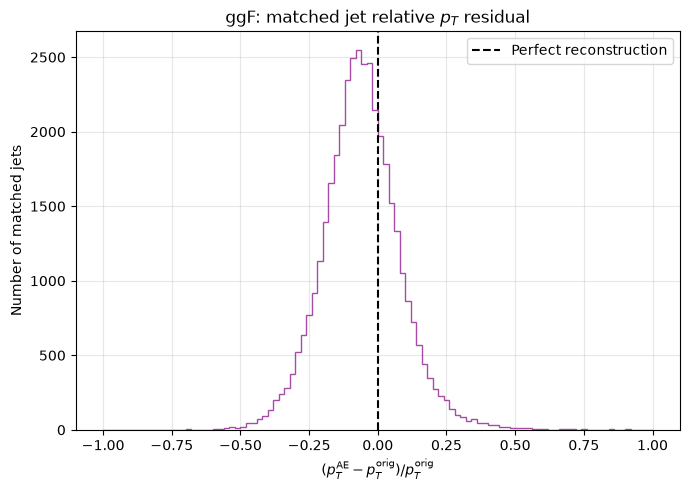

In [100]:
plt.figure(figsize=(7, 5))

plt.hist(
    relative_pt_residual,
    bins=100,
    range=(-1, 1),
    histtype="step",
    alpha=0.7,
    color = 'purple'
)



plt.axvline(
    0,
    linestyle="--",
    label="Perfect reconstruction",
    color = 'black'
)

plt.xlabel(
    r"$(p_T^{\mathrm{AE}}-p_T^{\mathrm{orig}})"
    r"/p_T^{\mathrm{orig}}$"
)

plt.ylabel("Number of matched jets")
plt.title(
    r"ggF: matched jet relative $p_T$ residual"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [101]:
outside_fraction = np.mean(
    (relative_pt_residual < -1)
    | (relative_pt_residual > 1)
)

print(
    "Fraction outside [-1, 1]:",
    outside_fraction
)

Fraction outside [-1, 1]: 0.0002563510984644569


LATENT SPACE EVALUATIONS

In [102]:
# bottleneck scan
if RUN_LATENT_SCAN:

    scan_results = {}

    for latent_channels in LATENT_CHANNEL_SCAN:

        print("\n" + "=" * 60)

        print(
            "Training latent channels:",
            latent_channels
        )

        print("=" * 60)

        best_lightning_model, result = (
            train_one_bottleneck(
                latent_channels=latent_channels,
                scale_gpu=scale_gpu,
                number_of_epochs=N_EPOCHS
            )
        )

        scan_results[
            latent_channels
        ] = result

        print(
            "Latent values:",
            result["latent_values"]
        )

        print(
            "Nominal compression ratio:",
            f"{result['nominal_compression_ratio']:.3f}"
        )

        print(
            "Best validation loss:",
            f"{result['best_val_loss']:.6f}"
        )

        del best_lightning_model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    torch.save(
        scan_results,
        "lightning_bottleneck_scan_results.pt"
    )

    print(
        "\nSaved scan results:",
        "lightning_bottleneck_scan_results.pt"
    )


In [103]:
# ============================================================
# VALIDATION LOSS AGAINST LATENT DIMENSION
# ============================================================

if RUN_LATENT_SCAN:

    ordered_channels = sorted(
        scan_results
    )

    latent_dimensions = np.array(
        [
            scan_results[c]["latent_values"]
            for c in ordered_channels
        ],
        dtype=int
    )

    best_val_losses = np.array(
        [
            scan_results[c]["best_val_loss"]
            for c in ordered_channels
        ],
        dtype=float
    )

    plt.figure(
        figsize=(9, 6)
    )

    plt.plot(
        latent_dimensions,
        best_val_losses,
        marker="o",
        markersize=7,
        linewidth=1.5,
        color = 'purple'
    )

    # Use the exact latent sizes as tick positions.
    plt.xticks(
        latent_dimensions,
        [
            f"{dimension:,}"
            for dimension in latent_dimensions
        ]
    )

    # Alternating positions prevent labels from overlapping.
    annotation_offsets = [
        (0, -52),
        (0, 15),
        (0, -52),
        (0, 15),
    ]

    for (
        channels,
        latent_dimension,
        validation_loss,
        offset
    ) in zip(
        ordered_channels,
        latent_dimensions,
        best_val_losses,
        annotation_offsets
    ):

        plt.annotate(
            (
                f"{channels} channels\n"
                f"{latent_dimension:,} latent values\n"
                f"loss = {validation_loss:.6f}"
            ),
            xy=(
                latent_dimension,
                validation_loss
            ),
            xytext=offset,
            textcoords="offset points",
            ha="center",
            fontsize=9,
            bbox={
                "boxstyle": "round,pad=0.3",
                "facecolor": "white",
                "alpha": 0.85,
                "edgecolor": "0.7"
            },
            arrowprops={
                "arrowstyle": "-",
                "linewidth": 0.6
            }
        )

    plt.xlabel(
        "Latent bottleneck size per event"
    )

    plt.ylabel(
        "Minimum validation loss"
    )

    plt.title(
        "Minimum Validation Loss versus Latent Bottleneck Size"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

In [104]:
#new
import pandas as pd

INPUT_VALUES = 6 * 50 * 64

ordered_channels = sorted(
    scan_results
)

comparison_rows = []

for channels in ordered_channels:

    latent_values = scan_results[
        channels
    ]["latent_values"]

    best_val_loss = scan_results[
        channels
    ]["best_val_loss"]

    compression_ratio = (
        INPUT_VALUES
        / latent_values
    )

    reduction_percent = (
        1.0
        - latent_values / INPUT_VALUES
    ) * 100.0

    comparison_rows.append(
        {
            "Latent channels":
                channels,

            "Latent values":
                latent_values,

            "Nominal compression ratio":
                compression_ratio,

            "Latent-value reduction (%)":
                reduction_percent,

            "Minimum validation loss":
                best_val_loss,
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    comparison_table.to_string(
        index=False,
        formatters={
            "Nominal compression ratio":
                lambda x: f"{x:.3f}:1",

            "Latent-value reduction (%)":
                lambda x: f"{x:.1f}",

            "Minimum validation loss":
                lambda x: f"{x:.6f}",
        }
    )
)

comparison_table.to_csv(
    "latent_bottleneck_comparison.csv",
    index=False
)

NameError: name 'scan_results' is not defined

In [ ]:
import pandas as pd

INPUT_VALUES = 6 * 50 * 64

ordered_channels = sorted(
    scan_results
)

comparison_rows = []

baseline_loss = scan_results[
    32
]["best_val_loss"]

for channels in ordered_channels:

    latent_values = scan_results[
        channels
    ]["latent_values"]

    best_val_loss = scan_results[
        channels
    ]["best_val_loss"]

    compression_ratio = (
        INPUT_VALUES
        / latent_values
    )

    reduction_percent = (
        1.0
        - latent_values / INPUT_VALUES
    ) * 100.0

    relative_loss_increase = (
        best_val_loss
        / baseline_loss
        - 1.0
    ) * 100.0

    comparison_rows.append(
        {
            "Latent channels":
                channels,

            "Latent values":
                latent_values,

            "Nominal compression ratio":
                compression_ratio,

            "Latent-value reduction (%)":
                reduction_percent,

            "Minimum validation loss":
                best_val_loss,

            "Loss increase relative to 32 channels (%)":
                relative_loss_increase,
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    comparison_table.to_string(
        index=False,
        formatters={
            "Nominal compression ratio":
                lambda x: f"{x:.3f}:1",

            "Latent-value reduction (%)":
                lambda x: f"{x:.1f}",

            "Minimum validation loss":
                lambda x: f"{x:.6f}",

            "Loss increase relative to 32 channels (%)":
                lambda x: f"{x:.1f}",
        }
    )
)

comparison_table.to_csv(
    "latent_bottleneck_comparison.csv",
    index=False
)

 Latent channels  Latent values Nominal compression ratio Latent-value reduction (%) Minimum validation loss Loss increase relative to 32 channels (%)
               4            768                  25.000:1                       96.0                0.008976                                      46.2
               8           1536                  12.500:1                       92.0                0.007245                                      18.0
              16           3072                   6.250:1                       84.0                0.008929                                      45.4
              32           6144                   3.125:1                       68.0                0.006140                                       0.0


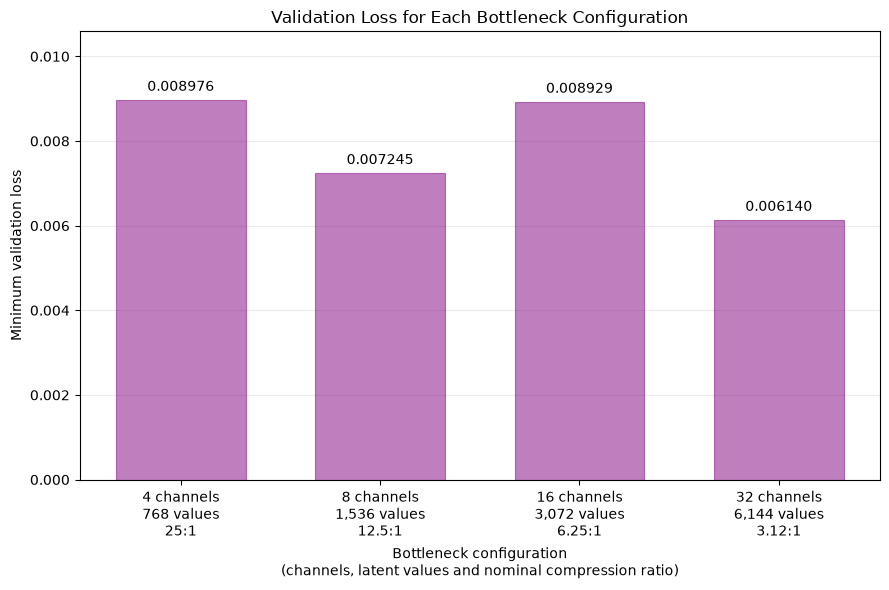

In [ ]:
# ============================================================
# VALIDATION LOSS BY BOTTLENECK CONFIGURATION
# ============================================================

if RUN_LATENT_SCAN:

    ordered_channels = sorted(
        scan_results
    )

    latent_values = [
        scan_results[c]["latent_values"]
        for c in ordered_channels
    ]

    validation_losses = [
        scan_results[c]["best_val_loss"]
        for c in ordered_channels
    ]

    compression_ratios = [
        scan_results[c]["nominal_compression_ratio"]
        for c in ordered_channels
    ]

    # Labels contain the three relevant bottleneck quantities.
    x_labels = [
        (
            f"{channels} channels\n"
            f"{values:,} values\n"
            f"{ratio:.3g}:1"
        )
        for channels, values, ratio in zip(
            ordered_channels,
            latent_values,
            compression_ratios
        )
    ]

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    bars = ax.bar(
        x_labels,
        validation_losses,
        width=0.65,
        alpha = 0.5,
        edgecolor="purple",
        linewidth=0.8,
        color = 'purple'
    )

    # Show exact validation loss above each bar.
    ax.bar_label(
        bars,
        labels=[
            f"{loss:.6f}"
            for loss in validation_losses
        ],
        padding=4,
        fontsize=10
    )

    ax.set_xlabel(
        "Bottleneck configuration\n"
        "(channels, latent values and nominal compression ratio)"
    )

    ax.set_ylabel(
        "Minimum validation loss"
    )

    ax.set_title(
        "Validation Loss for Each Bottleneck Configuration"
    )

    ax.set_ylim(
        0,
        max(validation_losses) * 1.18
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.set_axisbelow(
        True
    )

    plt.tight_layout()
    plt.show()

loading model for evaluation

In [ ]:
def load_autoencoder_for_evaluation(
    checkpoint_path,
    device
):
    '''
    Loads a Lightning checkpoint and returns the underlying
    ordinary PyTorch autoencoder.
    '''

    lightning_model = (
        LightningAutoencoder.load_from_checkpoint(
            checkpoint_path,
            map_location="cpu"
        )
    )

    model = (
        lightning_model
        .autoencoder
        .to(device)
    )

    model.eval()

    return model
